In [1]:
%pip install -q pandas numpy matplotlib scikit-learn imbalanced-learn

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SEED = 42

Note: you may need to restart the kernel to use updated packages.


In [2]:
df = pd.read_csv("train.csv")
print("Dataset size:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nTarget counts:\n", df["loan_status"].value_counts())
print("\nTarget %:\n", (df["loan_status"].value_counts(normalize=True) * 100).round(2))



Dataset size: (58645, 13)

Missing values:
 id                            0
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64

Target counts:
 loan_status
0    50295
1     8350
Name: count, dtype: int64

Target %:
 loan_status
0    85.76
1    14.24
Name: proportion, dtype: float64


In [3]:
# impossible values (123 years) -> missing, filled later by median
df["person_age"] = df["person_age"].astype(float)
df["person_emp_length"] = df["person_emp_length"].astype(float)
df.loc[df["person_age"] > 100, "person_age"] = np.nan
df.loc[df["person_emp_length"] > 60, "person_emp_length"] = np.nan
print("\nMissing after cleaning:", int(df.isna().sum().sum()))


Missing after cleaning: 3


In [4]:
print("Shape:", df.shape)
print("\nColumns and data types:\n", df.dtypes)
print("\nFirst 5 rows:")
display(df.head())
print("\nSummary statistics:")
display(df.describe().T.round(2))
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

for c in ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]:
    print(f"\n{c}:\n", df[c].value_counts())

Shape: (58645, 13)

Columns and data types:
 id                              int64
person_age                    float64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
loan_status                     int64
dtype: object

First 5 rows:


,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37.0,35000,RENT,0.0,EDUCATION,B,6000,11.49,0.17,N,14,0
1,1,22.0,56000,OWN,6.0,MEDICAL,C,4000,13.35,0.07,N,2,0
2,2,29.0,28800,OWN,8.0,PERSONAL,A,6000,8.90,0.21,N,10,0
3,3,30.0,70000,RENT,14.0,VENTURE,B,12000,11.11,0.17,N,5,0
4,4,22.0,60000,RENT,2.0,MEDICAL,A,6000,6.92,0.10,N,3,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
id,58645.0,29322.00,16929.50,0.00,14661.00,29322.00,43983.00,58644.00
person_age,58644.0,27.55,6.02,20.00,23.00,26.00,30.00,84.00
person_income,58645.0,64046.17,37931.11,4200.00,42000.00,58000.00,75600.00,1900000.00
person_emp_length,58643.0,4.70,3.90,0.00,2.00,4.00,7.00,41.00
loan_amnt,58645.0,9217.56,5563.81,500.00,5000.00,8000.00,12000.00,35000.00
loan_int_rate,58645.0,10.68,3.03,5.42,7.88,10.75,12.99,23.22
loan_percent_income,58645.0,0.16,0.09,0.00,0.09,0.14,0.21,0.83
cb_person_cred_hist_length,58645.0,5.81,4.03,2.00,3.00,4.00,8.00,30.00
loan_status,58645.0,0.14,0.35,0.00,0.00,0.00,0.00,1.00



Missing values per column:
 id                            0
person_age                    1
person_income                 0
person_home_ownership         0
person_emp_length             2
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64

Duplicate rows: 0

person_home_ownership:
 person_home_ownership
RENT        30594
MORTGAGE    24824
OWN          3138
OTHER          89
Name: count, dtype: int64

loan_intent:
 loan_intent
EDUCATION            12271
MEDICAL              10934
PERSONAL             10016
VENTURE              10011
DEBTCONSOLIDATION     9133
HOMEIMPROVEMENT       6280
Name: count, dtype: int64

loan_grade:
 loan_grade
A    20984
B    20400
C    11036
D     5034
E     1009
F      149
G       33
Name: count, dtype: int64

cb_person_default_on_file:
 cb_per

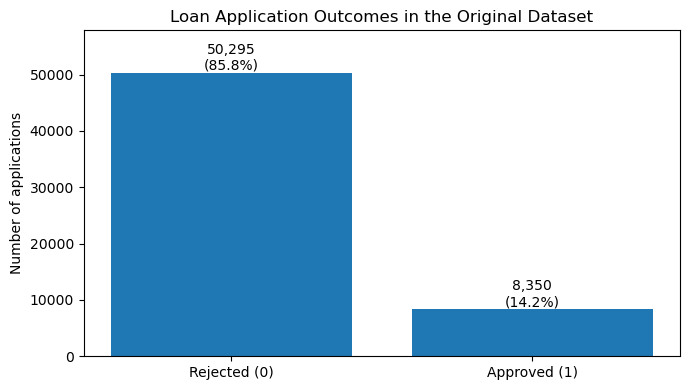

Counts: {0: 50295, 1: 8350}
This graph shows the original class imbalance; do not use resampled counts here.


In [5]:
# SECTION 1: Approved vs Rejected Applications
# Use the original dataset (before any resampling) to show the real class distribution.

target_counts = df["loan_status"].value_counts().reindex([0, 1], fill_value=0)
target_labels = ["Rejected (0)", "Approved (1)"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(target_labels, target_counts.values)
ax.set_title("Loan Application Outcomes in the Original Dataset")
ax.set_ylabel("Number of applications")
for bar, count in zip(bars, target_counts.values):
    pct = count / len(df) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, target_counts.max() * 1.15)
plt.tight_layout()
plt.show()

print("Counts:", target_counts.to_dict())
print("This graph shows the original class imbalance; do not use resampled counts here.")


In [6]:
NEW_FEATURES = ["employment_stability_ratio", "credit_maturity_ratio", "credit_profile_score",
                "loan_to_income_burden", "income_per_employment_year", "credit_history_coverage"]

def safe_div(a, b):
    out = a / b.where(b > 0)
    return out.replace([np.inf, -np.inf], np.nan)

def add_features(d):
    d = d.copy()
    d["employment_stability_ratio"] = safe_div(d["person_emp_length"], d["person_age"])
    d["credit_maturity_ratio"] = safe_div(d["cb_person_cred_hist_length"], d["person_age"])
    d["loan_to_income_burden"] = safe_div(d["loan_amnt"], d["person_income"])
    d["income_per_employment_year"] = safe_div(d["person_income"], d["person_emp_length"] + 1)
    d["credit_history_coverage"] = safe_div(d["cb_person_cred_hist_length"], d["person_emp_length"] + 1)

    income_pts  = 20 * (d["person_income"] / 100000).clip(0, 1)
    afford_pts  = 30 * (1 - (d["loan_percent_income"] / 0.5).clip(0, 1))
    emp_pts     = 15 * (d["person_emp_length"] / 10).clip(0, 1)
    history_pts = 20 * (d["cb_person_cred_hist_length"] / 15).clip(0, 1)
    default_pts = np.where(d["cb_person_default_on_file"] == "N", 15, 0)

    score = (income_pts.fillna(10) + afford_pts.fillna(15) + emp_pts.fillna(7.5)
             + history_pts.fillna(10) + default_pts)
    d["credit_profile_score"] = score.clip(0, 100)
    return d

df = add_features(df)
print(df[NEW_FEATURES].describe().T.round(3))
print("Score range:", round(df["credit_profile_score"].min(), 1), "to", round(df["credit_profile_score"].max(), 1))

                              count       mean        std      min       25%  \
employment_stability_ratio  58642.0      0.173      0.134    0.000     0.065   
credit_maturity_ratio       58644.0      0.197      0.095    0.047     0.125   
credit_profile_score        58645.0     59.476     13.086    9.467    50.967   
loan_to_income_burden       58645.0      0.160      0.094    0.001     0.089   
income_per_employment_year  58643.0  19049.270  22265.096  700.000  7300.000   
credit_history_coverage     58643.0      1.838      2.464    0.074     0.500   

                                  50%        75%          max  
employment_stability_ratio      0.143      0.273        0.953  
credit_maturity_ratio           0.174      0.267        1.036  
credit_profile_score           59.813     68.380       99.400  
loan_to_income_burden           0.142      0.209        3.125  
income_per_employment_year  11666.667  21666.667  1839784.000  
credit_history_coverage         1.000      2.000       

In [7]:
X = df.drop(columns=["id", "loan_status"])
y = df["loan_status"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=SEED)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED),
}

pipes = {name: ImbPipeline([("prep", prep), ("smote", SMOTE(random_state=SEED)), ("model", m)])
         for name, m in models.items()}

Train: (41051, 17) | Validation: (8797, 17) | Test: (8797, 17)


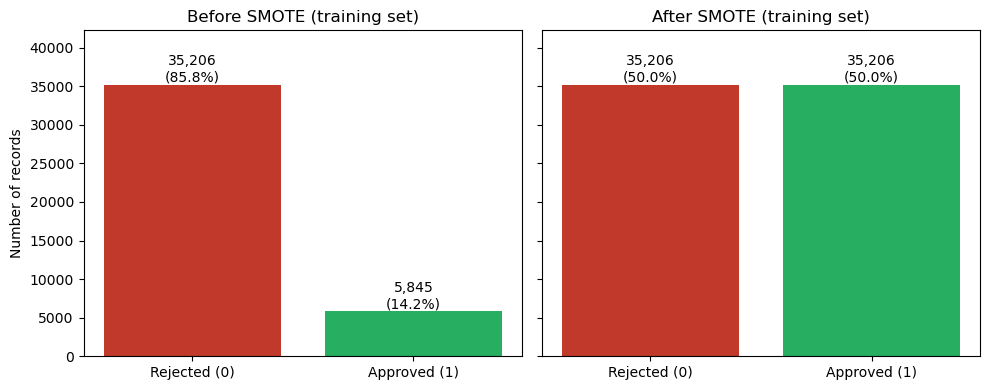

Before SMOTE: {0: 35206, 1: 5845}
After SMOTE : {0: 35206, 1: 35206}


In [8]:
X_train_t = clone(prep).fit_transform(X_train)
X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train_t, y_train)

before = y_train.value_counts().sort_index()
after = pd.Series(y_res).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, counts, title in zip(axes, [before, after], ["Before SMOTE (training set)", "After SMOTE (training set)"]):
    bars = ax.bar(["Rejected (0)", "Approved (1)"], counts.values, color=["#c0392b", "#27ae60"])
    for b, n in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}\n({n / counts.sum() * 100:.1f}%)",
                ha="center", va="bottom")
    ax.set_title(title)
    ax.set_ylim(0, before.max() * 1.2)
axes[0].set_ylabel("Number of records")
plt.tight_layout(); plt.show()

print("Before SMOTE:", before.to_dict())
print("After SMOTE :", after.to_dict())

In [9]:
rows = []
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_val)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_val, pred),
                 "Precision": precision_score(y_val, pred),
                 "Recall": recall_score(y_val, pred),
                 "F1": f1_score(y_val, pred),
                 "ROC-AUC": roc_auc_score(y_val, p)})

val_results = pd.DataFrame(rows).set_index("Model").round(4)
print(val_results)

best_name = val_results["F1"].idxmax()
best_pipe = pipes[best_name]
print("\nBest model on validation:", best_name)

                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.8456     0.4752  0.8107  0.5992   0.9007
Random Forest          0.9455     0.8869  0.7077  0.7872   0.9284
Gradient Boosting      0.9486     0.9008  0.7181  0.7991   0.9519

Best model on validation: Gradient Boosting


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8456,0.4752,0.8107,0.5992,0.9007
Random Forest,0.9455,0.8869,0.7077,0.7872,0.9284
Gradient Boosting,0.9486,0.9008,0.7181,0.7991,0.9519


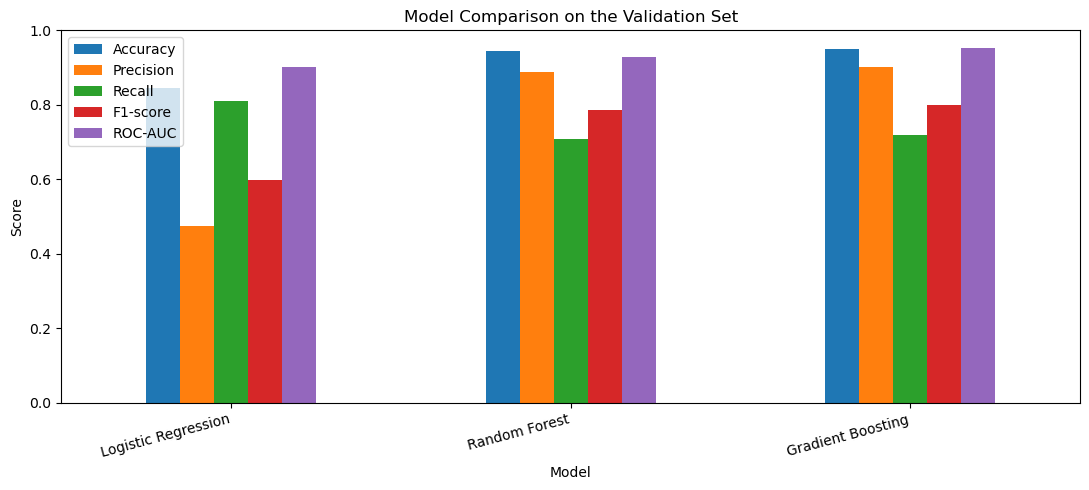

Best model selected by validation F1-score: Gradient Boosting


In [10]:
# SECTION 2: Validation Model Comparison
# Compare all models on the same validation split using simple, familiar metrics.

comparison_rows = []
validation_probabilities = {}
for name, pipe in pipes.items():
    probs = pipe.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.5).astype(int)
    validation_probabilities[name] = probs
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, preds),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "Recall": recall_score(y_val, preds, zero_division=0),
        "F1-score": f1_score(y_val, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probs)
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(model_comparison.round(4))

# Plot familiar metrics on the same 0-1 scale.
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = model_comparison[metrics_to_plot].plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
ax.set_title("Model Comparison on the Validation Set")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

print("Best model selected by validation F1-score:", model_comparison["F1-score"].idxmax())


,Model,Feature set,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,Original,0.4705,0.8083,0.5948,0.8995
1,Logistic Regression,Original + 6 derived,0.4752,0.8107,0.5992,0.9007
2,Random Forest,Original,0.8663,0.7141,0.7828,0.9340
3,Random Forest,Original + 6 derived,0.8869,0.7077,0.7872,0.9284
4,Gradient Boosting,Original,0.9026,0.7252,0.8043,0.9481
5,Gradient Boosting,Original + 6 derived,0.9008,0.7181,0.7991,0.9519


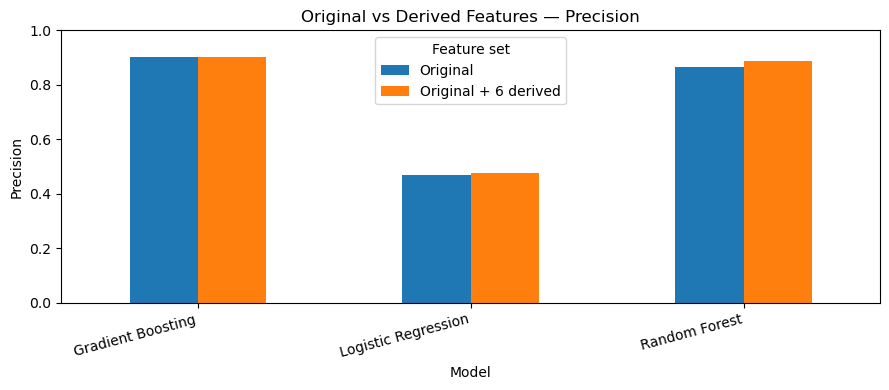

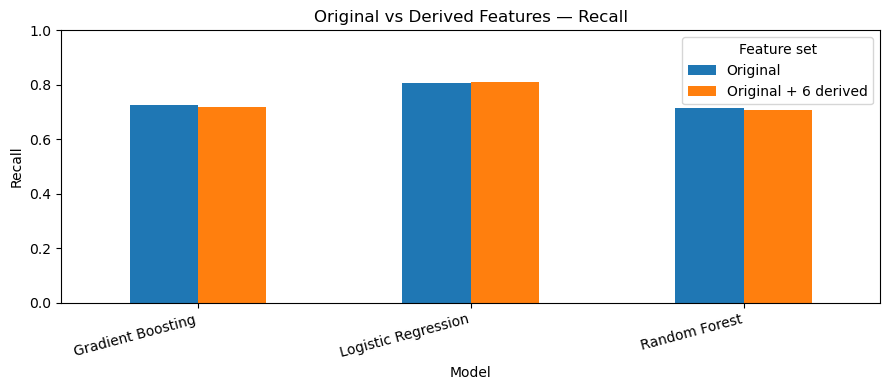

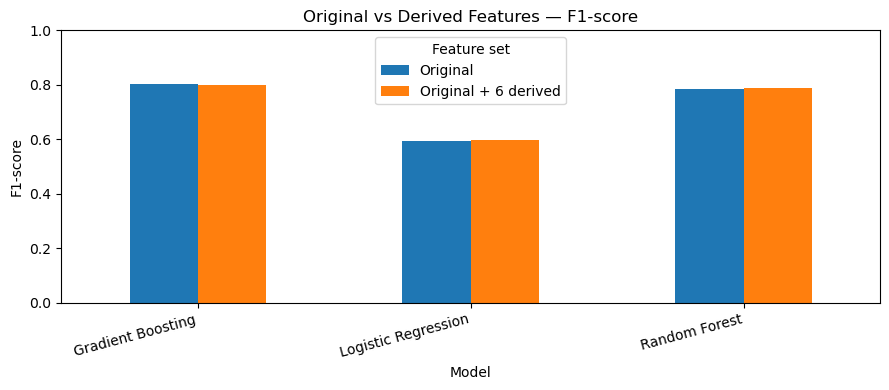

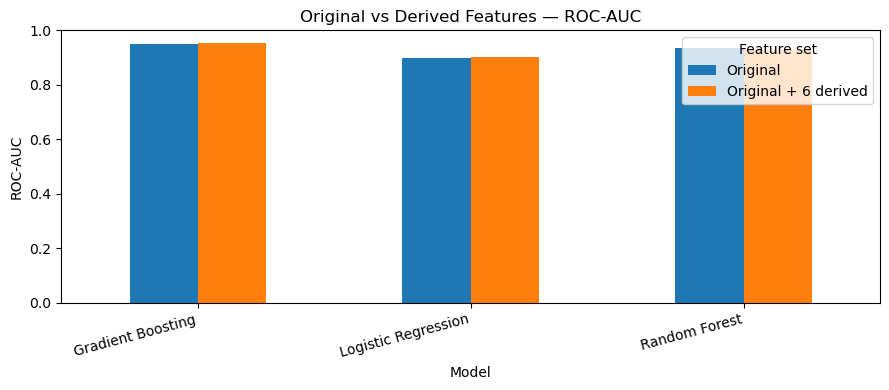

In [11]:
# SECTION 4: Original Features vs Original + Derived Features
# Use validation data only for this comparison. The held-out test set remains untouched.

orig_cols = [c for c in X.columns if c not in NEW_FEATURES]
num_o = [c for c in num_cols if c in orig_cols]
prep_o = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_o),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])

feature_rows = []
for name, estimator in models.items():
    original_pipe = ImbPipeline([("prep", clone(prep_o)), ("smote", SMOTE(random_state=SEED)),
                                 ("model", clone(estimator))])
    original_pipe.fit(X_train[orig_cols], y_train)
    p_original = original_pipe.predict_proba(X_val[orig_cols])[:, 1]
    p_derived = pipes[name].predict_proba(X_val)[:, 1]

    feature_rows.append({"Model": name, "Feature set": "Original",
                         "Precision": precision_score(y_val, p_original >= 0.5, zero_division=0),
                         "Recall": recall_score(y_val, p_original >= 0.5, zero_division=0),
                         "F1-score": f1_score(y_val, p_original >= 0.5, zero_division=0),
                         "ROC-AUC": roc_auc_score(y_val, p_original)})
    feature_rows.append({"Model": name, "Feature set": "Original + 6 derived",
                         "Precision": precision_score(y_val, p_derived >= 0.5, zero_division=0),
                         "Recall": recall_score(y_val, p_derived >= 0.5, zero_division=0),
                         "F1-score": f1_score(y_val, p_derived >= 0.5, zero_division=0),
                         "ROC-AUC": roc_auc_score(y_val, p_derived)})

feature_comparison = pd.DataFrame(feature_rows)
display(feature_comparison.round(4))

for metric in ["Precision", "Recall", "F1-score", "ROC-AUC"]:
    pivot = feature_comparison.pivot(index="Model", columns="Feature set", values=metric)
    ax = pivot.plot(kind="bar", figsize=(9, 4), ylim=(0, 1))
    ax.set_title(f"Original vs Derived Features — {metric}")
    ax.set_ylabel(metric)
    ax.set_xlabel("Model")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()


,Feature,Mean F1 decrease,Std
8,loan_percent_income,0.17020,0.00629
2,person_home_ownership,0.16386,0.00915
4,loan_intent,0.14699,0.00436
5,loan_grade,0.12531,0.00429
7,loan_int_rate,0.07091,0.00564
0,person_age,0.04517,0.00330
1,person_income,0.03976,0.00375
13,loan_to_income_burden,0.03081,0.00330
3,person_emp_length,0.02792,0.00272
12,credit_maturity_ratio,0.00255,0.00148


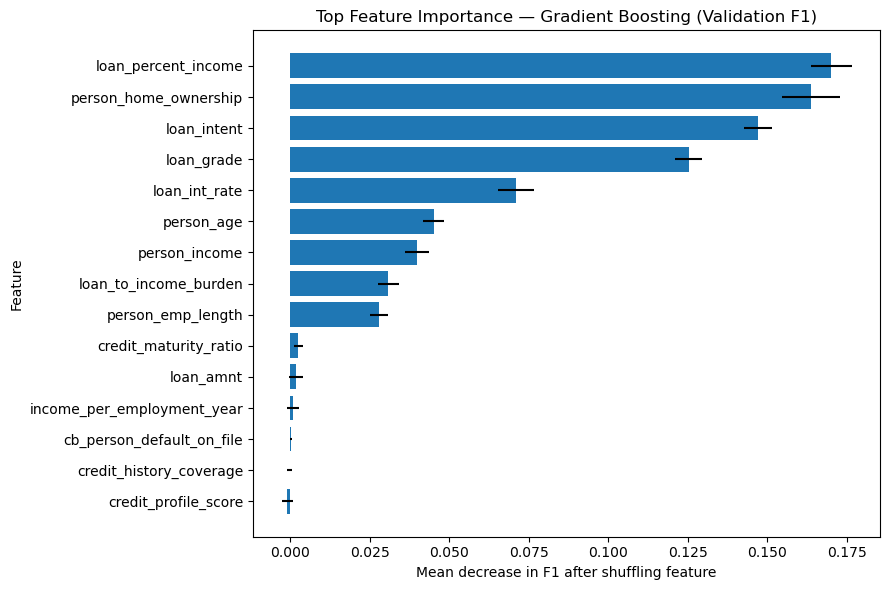

Interpretation: larger positive values mean shuffling that feature hurt F1 more.
This measures model reliance, not causation; negative values can occur.


In [14]:
# SECTION 3: Feature Importance (Permutation Importance)
# Shuffle one raw input feature at a time and measure the drop in validation F1-score.
# This works with the selected pipeline even when the estimator has no built-in feature_importances_.

perm = permutation_importance(
    best_pipe, X_val, y_val,
    scoring="f1", n_repeats=5, random_state=SEED, n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Mean F1 decrease": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Mean F1 decrease", ascending=False)

display(importance_df.round(5))

# Plot the 15 highest-ranked features for readability.
top_importance = importance_df.head(15).sort_values("Mean F1 decrease")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_importance["Feature"], top_importance["Mean F1 decrease"],
        xerr=top_importance["Std"])
ax.set_title(f"Top Feature Importance — {best_name} (Validation F1)")
ax.set_xlabel("Mean decrease in F1 after shuffling feature")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

print("Interpretation: larger positive values mean shuffling that feature hurt F1 more.")
print("This measures model reliance, not causation; negative values can occur.")


Final model: Gradient Boosting
Accuracy : 0.9525
Precision: 0.9179
Recall   : 0.7318
F1-score : 0.8144
ROC-AUC  : 0.9531

Confusion matrix:
 [[7462   82]
 [ 336  917]]

               precision    recall  f1-score   support

    Rejected       0.96      0.99      0.97      7544
    Approved       0.92      0.73      0.81      1253

    accuracy                           0.95      8797
   macro avg       0.94      0.86      0.89      8797
weighted avg       0.95      0.95      0.95      8797



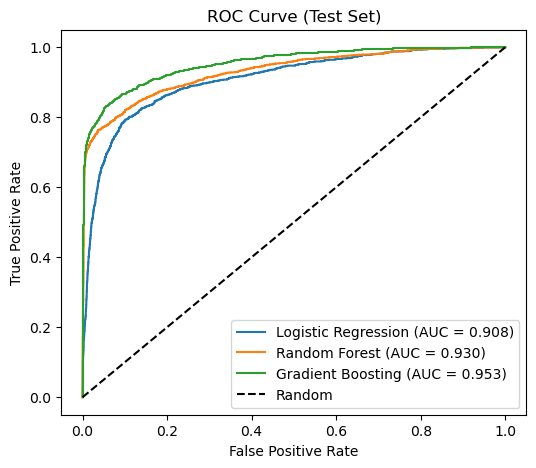

In [15]:
p = best_pipe.predict_proba(X_test)[:, 1]
pred = (p >= 0.5).astype(int)

print("Final model:", best_name)
print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("F1-score :", round(f1_score(y_test, pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, p), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_test, pred))
print("\n", classification_report(y_test, pred, target_names=["Rejected", "Approved"]))

plt.figure(figsize=(6, 5))
for name, pipe in pipes.items():
    pp = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pp)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, pp):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test Set)"); plt.legend(); plt.show()


In [16]:
applicant = add_features(pd.DataFrame([{
    "person_age": 25, "person_income": 30000, "person_home_ownership": "RENT",
    "person_emp_length": 1.0, "loan_intent": "MEDICAL", "loan_grade": "E",
    "loan_amnt": 15000, "loan_int_rate": 17.5, "loan_percent_income": 0.50,
    "cb_person_default_on_file": "Y", "cb_person_cred_hist_length": 3}]))[X.columns]

prob = best_pipe.predict_proba(applicant)[0, 1]
print("Probability of Approved:", round(prob, 4))
print("Prediction:", "Approved" if prob >= 0.5 else "Rejected")

Probability of Approved: 0.9989
Prediction: Approved
